# Next-month prediction — no 8-K

**Test notebook. Prediction only; no portfolio selection, sizing, or optimization.**

| Variant | Features | Training target |
|---|---|---|
| `current_gbm_no8k` | 147 monthly-ranked characteristics; missing values preserved | Current month-demeaned, clipped next-month excess return |
| `raw_return_gbm_no8k` | Identical features | Original next-month excess return |

The baseline reproduces the current **GBM branch**, excluding filings. It does not reproduce the annually selected linear/GBM blend. Raw-target predictions are in return units but are not guaranteed calibrated. Smoke results are functional checks, not performance evidence.

Setup from the repository root: `python -m pip install -r notebooks/requirements.txt`. Change `RUN_MODE` in Step 1 to `full` and run all cells for the complete comparison. Each run writes to its own output folder.

## 1. Configure comparison
Script: `02_prediction/03_train_predict.py; common/config.py`

In [10]:
from pathlib import Path
import sys, importlib.util, json, hashlib, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import lightgbm as lgb
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "02_prediction/03_train_predict.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from common import config as C

def load_script(name, relative):
    spec = importlib.util.spec_from_file_location(name, ROOT / relative)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

TRAIN = load_script("prediction_reference", "02_prediction/03_train_predict.py")
FEATURES = load_script("feature_reference", "01_data/02_make_features.py")

RUN_MODE = "full"  # "smoke": bounded 2021 check; "full": complete 2021–2026 folds
assert RUN_MODE in {"smoke", "full"}
SEED = 2026
TEST_YEARS = [2021] if RUN_MODE == "smoke" else list(range(2021, 2027))
MAX_TREES = 50 if RUN_MODE == "smoke" else TRAIN.GBM_FIXED["n_estimators"]
GRID = TRAIN.GBM_GRID[:1] if RUN_MODE == "smoke" else TRAIN.GBM_GRID
ROW_LIMITS = {"train": 20_000, "validation": 5_000, "test": 5_000}
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT = ROOT / "notebooks/outputs/next_month_prediction" / RUN_MODE / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
print(f"Mode: {RUN_MODE} | years: {TEST_YEARS} | output: {OUT}")
if RUN_MODE == "smoke":
    print("SMOKE TEST ONLY: sampled rows, reduced trees and grid. Do not use as strategy evidence.")

Mode: full | years: [2021, 2022, 2023, 2024, 2025, 2026] | output: c:\Users\tonyt\Documents\hackathonfiam_zzz\notebooks\outputs\next_month_prediction\full\20261028T190334784130Z


## 2. Load characteristics and align the next-month target
Script: `01_data/01_load_data.py → build_model_table`

In [11]:
feature_names = pd.read_csv(C.FACTOR_LIST_CSV)["variable"].tolist()
assert len(feature_names) == len(set(feature_names)) == 147
assert C.TARGET not in feature_names
source = C.CHARS_PARQUET
columns = ["permno", "eom", "ticker", "company_name", C.TARGET] + feature_names
data = pq.read_table(source, columns=columns).to_pandas()
data["eom"] = pd.to_datetime(data["eom"])
data["target_month"] = (data.eom.dt.to_period("M") + 1).astype(str)
data = data.sort_values(["target_month", "permno"]).reset_index(drop=True)
assert not data.duplicated(["permno", "target_month"]).any()
assert ((pd.PeriodIndex(data.target_month, freq="M") - 1).astype(str)
        == data.eom.dt.to_period("M").astype(str)).all()
assert not np.isinf(data[feature_names].to_numpy()).any(), "Infinite source feature values"
# ret_exc_lead1m is already led: do not shift its values again.
display(data[["permno", "ticker", "eom", "target_month", C.TARGET]].head())
print(f"{len(data):,} rows; {data.permno.nunique():,} securities; {len(feature_names)} inputs; no filing columns read.")

,permno,ticker,eom,target_month,ret_exc_lead1m
0,10001,EGAS,2015-01-31,2015-02,0.035918
1,10025,AEPI,2015-01-31,2015-02,0.010997
2,10026,JJSF,2015-01-31,2015-02,0.031309
3,10028,DGSE,2015-01-31,2015-02,-0.072827
4,10032,PLXS,2015-01-31,2015-02,0.062307


529,082 rows; 6,561 securities; 147 inputs; no filing columns read.


## 3. Rank features within month; preserve missing values
Script: `01_data/02_make_features.py → rank_keep_missing`

In [12]:
X = pd.DataFrame(np.nan, index=data.index, columns=feature_names, dtype="float32")
for _, indexes in data.groupby("target_month", sort=True).groups.items():
    ranked = data.loc[indexes, feature_names].apply(FEATURES.rank_keep_missing)
    X.loc[indexes, feature_names] = ranked.astype("float32")
assert X.columns.tolist() == feature_names
observed = X.to_numpy()
assert np.nanmin(observed) >= -1.0001 and np.nanmax(observed) <= 1.0001
print(f"Missing ranked inputs: {X.isna().mean().mean():.1%}; LightGBM handles them directly.")
display(X.head())

Missing ranked inputs: 10.8%; LightGBM handles them directly.


,age,aliq_at,aliq_mat,ami_126d,at_be,at_gr1,at_me,at_turnover,be_gr1a,be_me,...,taccruals_at,taccruals_ni,tangibility,tax_gr1a,turnover_126d,turnover_var_126d,z_score,zero_trades_126d,zero_trades_21d,zero_trades_252d
0,-0.288889,-0.377323,0.572979,0.329345,-0.139099,0.020098,0.396877,0.028142,-0.001767,0.663588,...,-0.091255,-0.431133,-0.292114,-0.593037,-0.216753,0.323905,-0.430303,0.202611,0.217952,-0.046171
1,-0.271111,-0.159232,0.333567,0.314659,0.615449,-0.658881,0.340872,0.917526,-0.750294,-0.416737,...,-0.363933,-0.818528,0.915457,-0.810324,-0.307588,0.141148,0.242105,0.290726,0.114217,0.103124
2,-0.271111,-0.180917,-0.479174,-0.269513,-0.848307,0.065182,-0.659666,0.618278,0.416372,-0.339491,...,0.053775,0.224124,0.258675,0.244298,-0.496872,-0.081860,0.841786,0.475116,0.218490,0.469173
3,-0.271111,-0.392193,-0.035352,0.932554,0.390428,-0.932102,-0.044157,0.966007,-0.925795,-0.390988,...,0.149919,0.412116,-0.187382,-0.785714,-0.792766,0.598586,-0.001595,0.920044,0.948401,0.911529
4,-0.288889,0.480793,0.580679,-0.247756,-0.090960,0.034221,0.121163,0.743104,0.348645,0.179961,...,0.775122,0.757675,0.433438,0.163866,-0.096002,-0.819962,0.304625,0.083492,-0.116367,0.138513


## 4. Freeze identical chronological splits for both models
Script: `common/config.py → training_schedule`

In [13]:
folds = []
for train_end, val_start, val_end, test_start, test_end in C.training_schedule():
    if int(test_start[:4]) not in TEST_YEARS:
        continue
    tm = data.target_month
    answered = data[C.TARGET].notna()
    indexes = {
        "train": data.index[(tm <= train_end) & answered].to_numpy(),
        "validation": data.index[(tm >= val_start) & (tm <= val_end) & answered].to_numpy(),
        "test": data.index[(tm >= test_start) & (tm <= test_end)].to_numpy(),
    }
    full_sizes = {k: len(v) for k, v in indexes.items()}
    if RUN_MODE == "smoke":
        rng = np.random.default_rng(SEED)
        indexes = {k: np.sort(rng.choice(v, min(len(v), ROW_LIMITS[k]), replace=False))
                   for k, v in indexes.items()}
    assert all(len(v) for v in indexes.values())
    assert tm.iloc[indexes["train"]].max() < tm.iloc[indexes["validation"]].min()
    assert tm.iloc[indexes["validation"]].max() < tm.iloc[indexes["test"]].min()
    folds.append(dict(year=int(test_start[:4]), train_end=train_end,
                      validation_start=val_start, validation_end=val_end,
                      test_start=test_start, test_end=test_end,
                      full_sizes=full_sizes, indexes=indexes))
display(pd.DataFrame([{k: v for k, v in f.items() if k != "indexes"}
                     | {f"used_{k}": len(v) for k, v in f["indexes"].items()} for f in folds]))

,year,train_end,validation_start,validation_end,test_start,test_end,full_sizes,used_train,used_validation,used_test
0,2021,2018-12,2019-01,2020-12,2021-01,2021-12,"{'train': 169285, 'validation': 85107, 'test':...",169285,85107,48037
1,2022,2019-12,2020-01,2021-12,2022-01,2022-12,"{'train': 211799, 'validation': 90458, 'test':...",211799,90458,52426
2,2023,2020-12,2021-01,2022-12,2023-01,2023-12,"{'train': 254392, 'validation': 100093, 'test'...",254392,100093,49828
3,2024,2021-12,2022-01,2023-12,2024-01,2024-12,"{'train': 302257, 'validation': 101705, 'test'...",302257,101705,46839
4,2025,2022-12,2023-01,2024-12,2025-01,2025-12,"{'train': 354485, 'validation': 96011, 'test':...",354485,96011,44424
5,2026,2023-12,2024-01,2025-12,2026-01,2026-08,"{'train': 403962, 'validation': 90711, 'test':...",403962,90711,28595


## 5. Fit current-target and raw-target LightGBM
Script: `02_prediction/03_train_predict.py → demean_and_clip; fit_gbm`

In [ ]:
def fit_variant(train_idx, val_idx, test_idx, raw_target):
    raw_train = data.loc[train_idx, C.TARGET].to_numpy()
    raw_val = data.loc[val_idx, C.TARGET].to_numpy()
    if raw_target:
        ytr, yva, offset = raw_train, raw_val, 0.0
    else:
        ytr = TRAIN.demean_and_clip(raw_train, data.loc[train_idx, "target_month"])
        yva = TRAIN.demean_and_clip(raw_val, data.loc[val_idx, "target_month"])
        offset = float(raw_train.mean())
    trials, best_model, best_loss = [], None, np.inf
    fixed = dict(TRAIN.GBM_FIXED)
    fixed.update(n_estimators=MAX_TREES, n_jobs=2, random_state=SEED,
                 deterministic=True, force_col_wise=True)
    for cfg in GRID:
        model = lgb.LGBMRegressor(**fixed, **cfg)
        model.fit(X.loc[train_idx], ytr, eval_set=[(X.loc[val_idx], yva)], eval_metric="l2",
                  callbacks=[lgb.early_stopping(TRAIN.GBM_EARLY_STOP, verbose=False)])
        loss = float(np.mean((yva - model.predict(X.loc[val_idx])) ** 2))
        trial = dict(config=cfg, validation_training_objective_mse=loss,
                     best_iteration=int(model.best_iteration_))
        trials.append(trial)
        if loss < best_loss:
            best_loss, best_model, best_trial = loss, model, trial
    return best_model, offset, dict(selected=best_trial, trials=trials)

predictions, training_log, importances = [], [], []
for fold in folds:
    tr, va, te = [fold["indexes"][k] for k in ("train", "validation", "test")]
    result = data.loc[te, ["permno", "ticker", "company_name", "eom", "target_month", C.TARGET]].copy()
    for name, raw_target in [("current_gbm_no8k", False), ("raw_return_gbm_no8k", True)]:
        model, offset, log = fit_variant(tr, va, te, raw_target)
        result[name] = model.predict(X.loc[te]) + offset
        assert np.isfinite(result[name]).all()
        model.booster_.save_model(str(OUT / f"{name}_{fold['year']}.txt"))
        training_log.append(dict(year=fold["year"], variant=name, prediction_offset=offset, **log))
        importances.append(pd.DataFrame({"feature": feature_names,
            "gain": model.booster_.feature_importance(importance_type="gain"),
            "variant": name, "year": fold["year"]}))
        print(f"{fold['year']} | {name} | {model.best_iteration_} trees", flush=True)
    predictions.append(result)
pred = pd.concat(predictions, ignore_index=True)
assert not pred.duplicated(["permno", "target_month"]).any()
# Missing future outcomes are retained and still receive predictions.
assert len(pred) == sum(len(f["indexes"]["test"]) for f in folds)
print(f"Predicted {len(pred):,} rows; {pred[C.TARGET].isna().sum():,} have unavailable future outcomes.")

c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


2021 | current_gbm_no8k | 57 trees


c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


2021 | raw_return_gbm_no8k | 1 trees


c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


2022 | current_gbm_no8k | 71 trees


c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


2022 | raw_return_gbm_no8k | 9 trees


c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\tonyt\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


## 6. Compare forecasts on the same original return target
Script: `02_prediction/03_train_predict.py → monthly_ic; write_metrics`

In [ ]:
variants = ["current_gbm_no8k", "raw_return_gbm_no8k"]
metric_rows, ic_rows = [], []
for scope, block in [("all", pred), *list(pred.groupby(pred.target_month.str[:4]))]:
    observed = block.dropna(subset=[C.TARGET])
    for name in variants:
        y, forecast = observed[C.TARGET], observed[name]
        monthly = observed.groupby("target_month").apply(
            lambda g: g[name].corr(g[C.TARGET], method="spearman")
                      if g[name].nunique() > 1 and g[C.TARGET].nunique() > 1 else np.nan,
            include_groups=False)
        denominator = float((y ** 2).sum())
        metric_rows.append(dict(scope=scope, variant=name, predicted_rows=len(block),
            scored_rows=len(observed), mse=float(((y - forecast)**2).mean()),
            oos_r2_vs_zero=1-float(((y-forecast)**2).sum())/denominator if denominator else np.nan,
            mean_monthly_rank_ic=monthly.mean(), scored_ic_months=int(monthly.notna().sum())))
        if scope == "all":
            ic_rows.extend(dict(target_month=m, variant=name, rank_ic=v) for m, v in monthly.items())
metrics = pd.DataFrame(metric_rows)
monthly_ic = pd.DataFrame(ic_rows)
display(metrics)
print("Both variants scored on original next-month excess returns. Training losses use different targets and are not directly comparable.")
if RUN_MODE == "smoke":
    print("Sampled-month demeaning and limited tuning are NOT the full production recipe; rerun with RUN_MODE='full'.")

,scope,variant,predicted_rows,scored_rows,mse,oos_r2_vs_zero,mean_monthly_rank_ic,scored_ic_months
0,all,current_gbm_no8k,5000,4978,0.047400,0.000237,0.153982,12
1,all,raw_return_gbm_no8k,5000,4978,0.047388,0.000495,0.102675,12
2,2021,current_gbm_no8k,5000,4978,0.047400,0.000237,0.153982,12
3,2021,raw_return_gbm_no8k,5000,4978,0.047388,0.000495,0.102675,12


Both variants scored on original next-month excess returns. Training losses use different targets and are not directly comparable.
Sampled-month demeaning and limited tuning are NOT the full production recipe; rerun with RUN_MODE='full'.


## 7. Plot prediction quality and feature importance
Script: `04_backtest_scoring/12_feature_importance.py; notebook comparison`

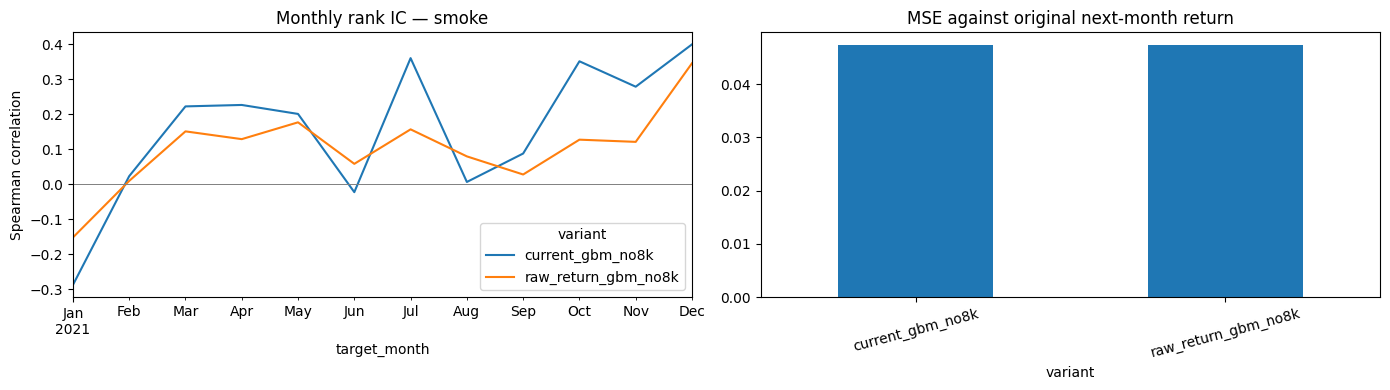

,variant,feature,mean_gain
69,current_gbm_no8k,mispricing_perf,7.619710
79,current_gbm_no8k,ni_me,6.070737
96,current_gbm_no8k,op_atl1,5.879307
44,current_gbm_no8k,eq_dur,4.588687
95,current_gbm_no8k,op_at,3.586650
110,current_gbm_no8k,rd_sale,2.970267
143,current_gbm_no8k,z_score,2.783125
78,current_gbm_no8k,ni_ivol,2.080635
103,current_gbm_no8k,prc_highprc_252d,2.001563
126,current_gbm_no8k,sale_emp_gr1,1.720182


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ic_chart = monthly_ic.pivot(index="target_month", columns="variant", values="rank_ic")
ic_chart.index = pd.PeriodIndex(ic_chart.index, freq="M").to_timestamp()
ic_chart.plot(ax=axes[0], title=f"Monthly rank IC — {RUN_MODE}")
axes[0].axhline(0, color="gray", linewidth=.7)
axes[0].set_ylabel("Spearman correlation")
summary = metrics[metrics.scope.eq("all")].set_index("variant")
summary[["mse"]].plot.bar(ax=axes[1], legend=False, title="MSE against original next-month return")
axes[1].tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(OUT / "prediction_comparison.png", dpi=140)
plt.show()
importance = pd.concat(importances, ignore_index=True)
display(importance.groupby(["variant", "feature"]).gain.mean().rename("mean_gain")
        .reset_index().sort_values(["variant", "mean_gain"], ascending=[True, False])
        .groupby("variant").head(10))

## 8. Optionally compare the saved production forecasts
Script: `02_prediction/03_train_predict.py → predictions.parquet`

In [ ]:
saved = C.PROCESSED_DIR / "predictions.parquet"
if not saved.exists():
    print("No saved production predictions found. The controlled no-8K GBM comparison above is available.")
else:
    original = pd.read_parquet(saved, columns=["permno", "target_month", "gbm", "avg"])
    assert not original.duplicated(["permno", "target_month"]).any()
    matched = pred.merge(original.rename(columns={"gbm": "saved_gbm", "avg": "saved_blend_score"}),
                         on=["permno", "target_month"], how="inner", validate="one_to_one")
    print(f"Matched {len(matched):,}/{len(pred):,} test rows. Saved provenance/8-K inclusion must be checked separately.")
    rows = []
    for col in variants + ["saved_gbm", "saved_blend_score"]:
        scored = matched.dropna(subset=[C.TARGET, col])
        ic = scored.groupby("target_month").apply(
            lambda g: g[col].corr(g[C.TARGET], method="spearman")
                      if g[col].nunique() > 1 and g[C.TARGET].nunique() > 1 else np.nan,
            include_groups=False)
        rows.append({"variant": col, "matched_scored_rows": len(scored), "mean_monthly_rank_ic": ic.mean()})
    display(pd.DataFrame(rows))
    print("Saved avg is a ranking score: do not interpret it as a return forecast or calculate return MSE on it.")

No saved production predictions found. The controlled no-8K GBM comparison above is available.


## 9. Save isolated test outputs
Script: `notebooks/outputs/next_month_prediction/ — production files untouched`

In [ ]:
pred.to_parquet(OUT / "predictions.parquet", index=False)
pred.to_csv(OUT / "predictions.csv", index=False)
metrics.to_csv(OUT / "metrics.csv", index=False)
monthly_ic.to_csv(OUT / "monthly_rank_ic.csv", index=False)
importance.to_csv(OUT / "feature_importance.csv", index=False)
(OUT / "training_choices.json").write_text(json.dumps(training_log, indent=2), encoding="utf-8")
manifest = {"run_mode": RUN_MODE, "seed": SEED, "test_years": TEST_YEARS,
    "max_trees": MAX_TREES, "grid": GRID, "features": feature_names, "filing_features": False,
    "target": C.TARGET, "source": str(source), "source_bytes": source.stat().st_size,
    "source_mtime_ns": source.stat().st_mtime_ns,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "lightgbm": lgb.__version__},
    "script_sha256": {s: hashlib.sha256((ROOT/s).read_bytes()).hexdigest() for s in
       ["02_prediction/03_train_predict.py", "01_data/02_make_features.py", "common/config.py"]},
    "folds": [{k: v for k, v in f.items() if k != "indexes"} for f in folds]}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(f"Saved comparison: {OUT}")
print("Next stage: validate/calibrate forecasts, then test the sizing optimizer separately.")

Saved comparison: c:\Users\tonyt\Documents\hackathonfiam_zzz\notebooks\outputs\next_month_prediction\smoke\20261028T185854169416Z
Next stage: validate/calibrate forecasts, then test the sizing optimizer separately.
